# Student performance

The goal of this project is to choose and train a machine learning model to predict student grades based on their socio-economic status.
___

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

At the start, we import the dataset from the Excel file, align the two sheets correctly and merge them into a dataframe.

In [40]:
portuguese = pd.read_excel("student_performance.xlsx", sheet_name=0, header=2)
math = pd.read_excel("student_performance.xlsx", sheet_name=1, header=1)

portuguese = portuguese.dropna(axis=1, how="all")
math = math.dropna(axis=1, how="all")

data = pd.concat([portuguese, math], axis=0)

In [41]:
data.head()

,id,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,56,GP,F,15.0,U,GT3,A,4.0,3.0,services,...,4.0,3.0,2.0,1.0,1.0,1.0,0.0,15,14,15
1,192,GP,M,16.0,R,GT3,T,4.0,2.0,teacher,...,4.0,3.0,3.0,3.0,4.0,3.0,8.0,10,9,11
2,494,MS,F,16.0,R,LE3,T,1.0,2.0,at_home,...,4.0,4.0,5.0,1.0,3.0,3.0,0.0,8,9,9
3,404,GP,F,17.0,U,GT3,T,2.0,1.0,services,...,4.0,3.0,5.0,2.0,4.0,4.0,4.0,12,16,16
4,355,GP,F,17.0,U,GT3,T,2.0,3.0,other,...,4.0,2.0,1.0,1.0,1.0,3.0,2.0,11,12,14


### Data analysis
___

In [42]:
data.describe()

,id,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,1149.000000,1141.000000,1139.000000,1138.000000,1144.000000,1142.000000,1141.000000,1141.000000,1148.000000,1139.000000,1134.000000,1144.000000,1144.000000,1141.000000,1149.000000,1149.000000,1149.000000
mean,273.389904,16.729185,2.601405,2.400703,1.513112,1.959720,0.260298,3.917616,3.197735,3.156277,1.477954,2.283217,3.526224,4.397897,11.189730,11.200174,11.285466
std,173.868771,1.236619,1.121384,1.100603,0.730419,0.824763,0.645967,0.951571,1.035597,1.155024,0.890743,1.277793,1.433023,5.969172,2.988456,3.337304,3.915747
min,0.000000,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,128.000000,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,9.000000,9.000000,10.000000
50%,256.000000,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,11.000000
75%,388.000000,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,648.000000,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [43]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1149 entries, 0 to 434
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1149 non-null   int64  
 1   school      1149 non-null   object 
 2   sex         1149 non-null   object 
 3   age         1141 non-null   float64
 4   address     1146 non-null   object 
 5   famsize     1141 non-null   object 
 6   Pstatus     1136 non-null   object 
 7   Medu        1139 non-null   float64
 8   Fedu        1138 non-null   float64
 9   Mjob        1144 non-null   object 
 10  Fjob        1143 non-null   object 
 11  reason      1139 non-null   object 
 12  guardian    1142 non-null   object 
 13  traveltime  1144 non-null   float64
 14  studytime   1142 non-null   float64
 15  failures    1141 non-null   float64
 16  schoolsup   1144 non-null   object 
 17  famsup      1143 non-null   object 
 18  paid        1142 non-null   object 
 19  activities  1136 non-null   objec

We can see that the data includes 30 attributes, which are either a number or an object. The description provided with the dataset shows that both numeric and object types come in a number of different variants:

**Numeric**
- Number - age, absences
- Ordinal encoding 0/1-4 - mother's education, father's education, travel time, study time, failures (0-3 is the number of failures, 4 means 4 or higher)
- Scale 1-5 - family relationship, freetime, going out, workday and weekday alcohol consumption, health

**Object**
- Binary - school, sex, address, family size, parent's cohab. status, school support, family support, paid classes, extra activities, nursery, seeking higher ed., internet access, romantic relationship
- Nominal - mother's job, father's job, reason, guardian

Our class to predict is the final grade, represented as column G3 in the dataset. This is numerical value, an integer 0-20.

Now, let's check how many empty values we have at most

In [44]:
max = 0
rows = 1149

for col in data.columns:
    max = max if max > (rows - data[col].count()) else rows - data[col].count()
print(max)

15


We can see that the highest amount of missing values in a column is 15, which is approximately 0.1% of the entire dataset, so missing values can be simply added by imputing.

___
Let's create a histogram of G3 to see the distribution of the classes.

<Axes: >

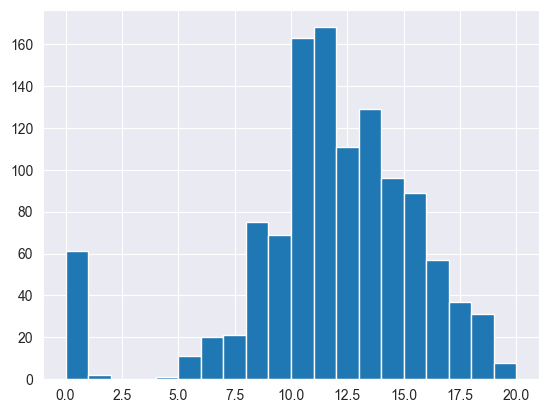

In [45]:
data['G3'].hist(bins=20)

The histogram shows what looks to be a normal distribution of classes, shifted slightly towards higher values. We can also see a lack of values 2 and 3, which means that the resulting model won't be able to predict them.
___

The description tells us what number of different values can each attribute be. We will list the number of unique values in each column to check.

In [46]:
data.nunique()

id            649
school          2
sex             2
age             8
address         2
famsize         2
Pstatus         2
Medu            5
Fedu            5
Mjob            5
Fjob            5
reason          4
guardian        3
traveltime      4
studytime       4
failures        4
schoolsup       5
famsup          6
paid            6
activities      6
nursery         6
higher          5
internet        6
romantic        6
famrel          5
freetime        5
goout           5
Dalc            5
Walc            5
health          5
absences       34
G1             18
G2             17
G3             19
dtype: int64

We can see that in the columns *schoolsup*, *famsup*, *paid*, *activities*, *nursery*, *higher*, *internet* and *romantic*, there are 5 or 6 unique values, even though we are only expecting a binary *yes* or *no*. Let's list these unique values.

In [47]:
binary_cols = ['schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
for col in binary_cols:
    print(col, ' ', np.unique(data[col].astype(str)).tolist())

schoolsup   ['0', 'nan', 'no', 'não', 'sim', 'yes']
famsup   ['0', '1', 'nan', 'no', 'não', 'sim', 'yes']
paid   ['0', '1', 'nan', 'no', 'não', 'sim', 'yes']
activities   ['0', '1', 'nan', 'no', 'não', 'sim', 'yes']
nursery   ['0', '1', 'nan', 'no', 'não', 'sim', 'yes']
higher   ['1', 'nan', 'no', 'não', 'sim', 'yes']
internet   ['0', '1', 'nan', 'no', 'não', 'sim', 'yes']
romantic   ['0', '1', 'nan', 'no', 'não', 'sim', 'yes']


Next to the expected *yes* and *no*, some answers were provided in portuguese, i.e. *não (no)* and *sim (yes)* or as numbers *0* and *1*. There are also some missing values. These values will have to be unified later.


In [48]:
data.nunique(dropna=True)

id            649
school          2
sex             2
age             8
address         2
famsize         2
Pstatus         2
Medu            5
Fedu            5
Mjob            5
Fjob            5
reason          4
guardian        3
traveltime      4
studytime       4
failures        4
schoolsup       5
famsup          6
paid            6
activities      6
nursery         6
higher          5
internet        6
romantic        6
famrel          5
freetime        5
goout           5
Dalc            5
Walc            5
health          5
absences       34
G1             18
G2             17
G3             19
dtype: int64

After dropping missing values, we can see that the rest of the attributes have the expected number of unique values as defined by the description.
___

Now, let's create a correlation matrix of all the numerical values, excluding *id*.

<Axes: >

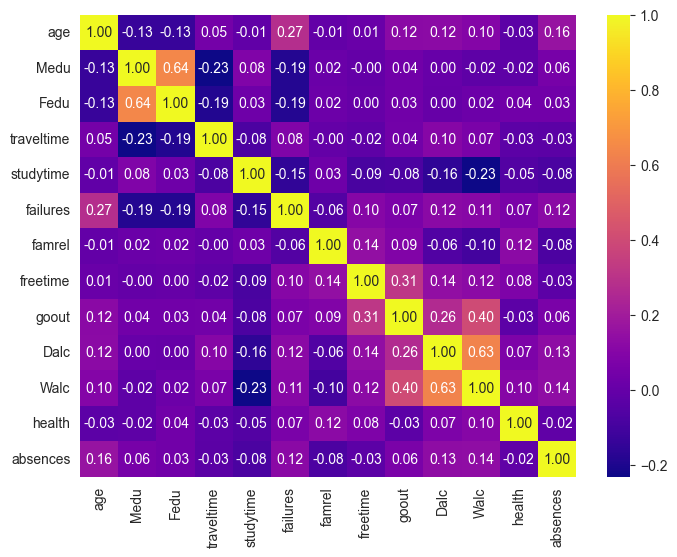

In [49]:
corr_mat = data[['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_mat, cmap='plasma', annot=True ,fmt=".2f")

The highest correlation seems to be between the mothers and fathers education. Closely following is workday and weekend alcohol consumption. There is also some correlation between free time and time spent going out, and going out and weekend alcohol consumption.  We can also see that the number of failures tends to go up with age.

## Preprocessing

In our project, we will be implementing a Decision tree and a neural network. Firstly, we will have to do some data preprocessing.
___

At the start we will split the data into the input and output. We will also clean the data, more specifically the aforementioned binary columns that include multiple versions of the same answer. This is necessary, because otherwise, the models would assume it means different things, even though they're the same. We can do this data cleaning before the train test split, because it doesn't affect the relationship between the rows.

In [50]:
X = data.drop(columns=['G1', 'G2', 'G3'])
y = data['G3']

X[binary_cols] = X[binary_cols].replace({'no': 0, 'não': 0, 'sim': 1, 'yes': 1})
X = X.replace({'nan': np.nan})

### Splitting into training a testing data

The modifications we will be applying next would leak some information from the testing data into the training data, so we must split the dataset. We set the test size to 0.2, which leaves with a testing set of approximately 230 entries, while still leaving enough training data.


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=24)

Now, we have to do modifications to the data to prepare it for using in the models. The tools we will use will depend on the type og the column. All columns will have to be imputed for missing values. Then, the categorical columns will have to be encoded, and the numerical columns scaled.


In [52]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer

numerical_cols = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures',
                  'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health',
                  'absences']

binary_cols = ['school', 'sex', 'address', 'famsize', 'Pstatus',
               'schoolsup', 'famsup', 'paid', 'activities',
               'nursery', 'higher', 'internet', 'romantic']

nominal_cols = ['Mjob', 'Fjob', 'reason', 'guardian']

X_train[binary_cols] = X_train[binary_cols].astype(str)
X_test[binary_cols] = X_test[binary_cols].astype(str)

numerical_pipeline = make_pipeline(
    SimpleImputer(strategy='mean'),
)

binary_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OrdinalEncoder()
)

nominal_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

transformer = make_column_transformer(
    (numerical_pipeline, numerical_cols),
    (binary_pipeline, binary_cols),
    (nominal_pipeline, nominal_cols),
    remainder='drop'
)

preprocessor = make_pipeline(
    transformer,
    StandardScaler()
)

We have created a pipeline for each type of column. All of them include a SimpleImputer. As mentioned before, we have a few missing field in all columns, but the number is small that imputing them will not have a large effect on the dataset a will enable us to use data that would have to be thrown out otherwise.

Next, we scaled the numerical columns between 0 and 1. The decision tree isn't sensitive to scale difference, but neural networks are. The reason to scale between 0 and 1 is that ordinal encoded binary columns and one hot encoded columns are already between 0 and 1 and won't have to be scaled.

We used an OrdinalEncoder on the binary columns. The ones we cleand beforehand were already 0 and 1, but the rest had all different form, so this way, we unified them to 0 and 1.

Lastly nominal columns were one hot encoded. One hot encoding creates a column for each possible label, which removes the scale between them, because the labels can't be compared numerically. Finally, we use StandardScaler to scale the values, mainly because of the neural network.

___

Now, we will fit the preprocessor, first for the training dataset, and then for the testing one.

In [53]:
preprocessor.fit(X_train)

X_train_nn = pd.DataFrame(preprocessor.transform(X_train))
X_train_dt = pd.DataFrame(preprocessor.transform(X_train))

preprocessor.fit(X_test)

X_test_nn = pd.DataFrame(preprocessor.transform(X_test))
X_test_dt = pd.DataFrame(preprocessor.transform(X_test))

As for more advanced preprocessing, we cannot add any data, as it is a result of an experiment, and we don't have any viable way to create new answers. Feature selection is not necessary for a neural network, but we will experiment with it with decision trees


## Neural Network

A neural network is a machine learning model inspired by the structure of the human brain, consisting of layers of interconnected "neurons" or nodes. Each connection has an associated weight that determines the strength of the connection between neurons. During training, the network learns to adjust these weights based on the data it receives. The process begins by feeding input data through the network, and each neuron performs a weighted sum of its inputs followed by an activation function to produce its output. This output propagates through the layers until a final prediction or classification is made in the output layer.

The goal of training is to minimize the difference between the network's predictions and the actual target values. This is done by calculating a loss function, which measures the error in the prediction. Backpropagation, a key technique in training, computes the gradient of the loss with respect to each weight and uses gradient descent or a similar optimization method to adjust the weights. This iterative process continues until the network's performance on the training data reaches an acceptable level, with the result being a set of weights that allow the neural network to make accurate predictions on new, unseen data.



In [54]:
import torch
from torch.utils.data import Dataset, DataLoader
from statistics import mean
from sklearn.metrics import accuracy_score, confusion_matrix, root_mean_squared_error
import tqdm
torch.manual_seed(24)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

For the neural network. We will be using the PyTorch library. At the beginning, we have to create a class for our dataset. It will inherit from the PyTorch class Dataset. We have to define a constructor, length method and getitem method. The constructor simply assigns the input and output, len returns the number of rows and getitem returns a tuple of a tensor of inputs and the output at the given index. We divide the output by 20, which will normalize our result classes, and we will multiply by 20 upon evaluation.

In [77]:
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return torch.tensor(self.X.iloc[idx], dtype=torch.float32), self.y.iloc[idx].astype(np.float32) / 20

Then, we create an instance of our dataset and put it into a dataloader. The dataloader allows us to easily train our network in batches. It is iterable, and each iteration gives a batch of a specified size. We do the same for the testing data, which will be used later.

In [78]:
nn_train_dataset = MyDataset(X_train_nn, y_train)
nn_test_dataset = MyDataset(X_test_nn, y_test)

train_dataloader = DataLoader(nn_train_dataset, batch_size=128, shuffle=True)
test_dataloader = DataLoader(nn_test_dataset, batch_size=1)

Now, we have to define how will our network look. The size of the first and last layers has to match the dataset and the output. The layers inbetween (hidden layers) are up to us. Let's create a class, that takes the layers sizes in the constructor.

In [79]:
class Model(torch.nn.Module):
    def __init__(self, d_in, d_out, layer_sizes):
        super().__init__()
        layers = []
        current_dim = d_in

        for h in layer_sizes:
            layers.append(torch.nn.Linear(current_dim, h))
            layers.append(torch.nn.ReLU())
            current_dim = h

        layers.append(torch.nn.Linear(current_dim, d_out))
        self.model = torch.nn.Sequential(*layers)
        self.sigmoid = torch.nn.Sigmoid()


    def forward(self, x):
        return self.sigmoid(self.model(x))

For each hidden layer, we will create a layer of the given number of neurons. Then, we apply ReLu, which takes away the linearity, allowing the network to model complex functions. Finally, we add a sigmoid to ensure the result is between 0 and 1. We then create an instance of our model with the following layer sizes:
128, 256, 512, 256, 128.
___

The training works using back propagation. After each batch, we use the model, find the gradient and go in the other direction. When all the batches finish, we evaluate the model using the test dateset. Normally, we would use a separate validation dataset for this, to leave the testing one untouched, however, due to our very small dataset, we decided to use the testing. We go through the dataset and calculate the loss in each epoch.

___

There is a huge number of different hyperparameters we can set in a neural network. Starting with the learning rate, which decides by how much we move in each change in the weights. We can also choose the size of the batches and number of epochs. If you don't have enough epochs, you risk underfitting. On the other hand, too many epochs can lead to overfitting.

Finally, we can choose the number and size of each layer. Unfortunately, the amount of different options is so large, that systematically testing all of them is very hard. For that reason, we will set only one network structure and then try tuning the learning rate and number of epochs. We tried training with 25 to 1000 epochs, and found out that the best range is around 300.
___
Now, let's begin training. We use tqdm to see the training progress. We specify the criterion we use for training and the optimizer. Then, in each epoch we go through all the batches, calculate the gradient and go backwards. We also collect the loss of each epoch to see how we progressed.


100%|██████████| 300/300 [00:49<00:00,  6.10it/s]


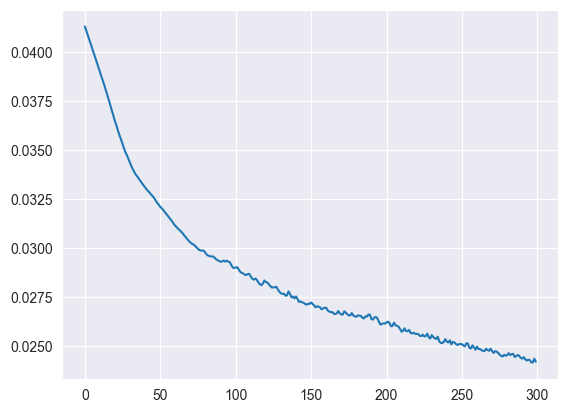

In [80]:
model = Model(X_train_nn.shape[1], 1, [128, 256, 512, 256, 128])

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.00001)

mean_losses = []
for epoch in tqdm.tqdm(range(300)):

    model.train()
    for batch in train_dataloader:
        features, labels = batch

        optimizer.zero_grad()

        prediction = model(features)
        loss = criterion(prediction, labels.unsqueeze(1))
        loss.backward()

        optimizer.step()

    model.eval()

    epoch_losses = []

    with torch.no_grad():
        for batch in test_dataloader:
            features, labels = batch

            prediction = model(features)
            loss = criterion(prediction, labels.unsqueeze(1))
            epoch_losses.append(loss.item())

    mean_loss = mean(epoch_losses)
    mean_losses.append(mean_loss)

plt.plot(mean_losses)
plt.show()

We can see that at the start, the loss decrease was very large. It then begins to flatten. If we were to continue, the loss would start to go up, which would be a sign of overfitting. Now, we will go through the testing dataset and evaluate.

### Interpretation

Interpreting a neural network is very hard, as it is a so called 'black box'. There isn't really a good way to look at the values inside the network a interpret them. However, we can look at the graphs. We can see that the results mostly predict values around the middle, i.e 10-14. This makes sense, as the dataset is very unbalances, so for all intents and purposes, values at the edges of the grading scale are almost nonexistent. We can see that the scale on to box plot doesn't even go all the way to the edges.

Neural networks are one of, if not the most advanced ML models out there. However, they require a large dataset and somewhat balanced data to produce good results. Our training dataset, having less than 1000 entries, is incredibly small relative to neural networks.

However, what we can do, is analyze the distribution of predictions. One possible method is a confusion matrix. In an ideal scenario, all non-zero elements should lie on the main diagonal. Since we're aiming not only for getting a spot-on prediction, but also being close if we're wrong. We can see, that most of our values are on the main diagonal, close to the center of the matrix, which is explainable given the unevenly distributed dateset. What's more interesting, is that even though there were plenty of students, who received a 0, the neural network failed to predict any of them. This is even more visible in the box plot, which shows that most 0's in the test set were predicted somewhere between 5 and 10, and it didn't predict values higher than 16. Again, this is likely caused by the unbalanced dataset.

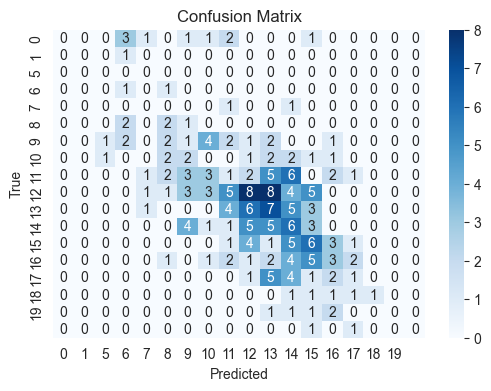

Accuracy 0.1608695652173913
RMSE 3.0983866769659336


In [81]:
results = []
model.eval()

with torch.no_grad():
        for batch in test_dataloader:
            features, labels = batch

            prediction = model(features)
            results.append((labels[0].item(), prediction.item()))

# 1. confusion matrix
gt = [round(20 * x) for x, _ in results]
y_pred_nn = [round(20 * x) for _, x  in results]

cm = confusion_matrix(gt, y_pred_nn)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(gt), yticklabels=np.unique(gt))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# 2. accuracy
print(f'Accuracy {accuracy_score(y_pred_nn, gt)}')
print(f'RMSE {root_mean_squared_error(y_pred_nn, gt)}')

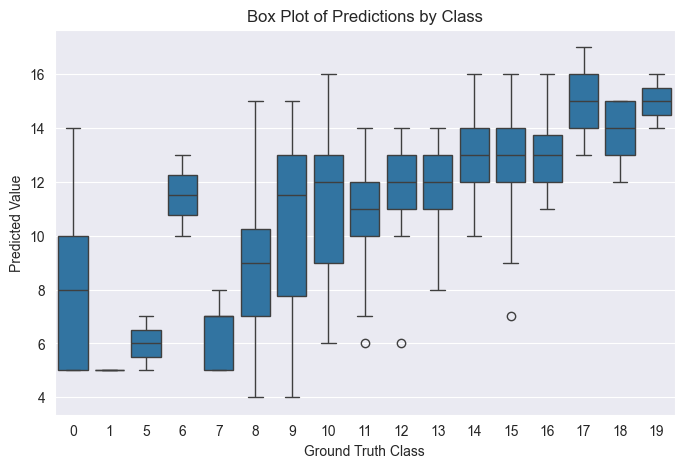

In [82]:
result = pd.DataFrame({'ground_truth': gt, 'prediction': y_pred_nn})

plt.figure(figsize=(8, 5))
sns.boxplot(data=result, x='ground_truth', y='prediction')
plt.title('Box Plot of Predictions by Class')
plt.xlabel('Ground Truth Class')
plt.ylabel('Predicted Value')
plt.show()